# Experimentos: forma de trayectoria y embeddings

El notebook 05 mostro que, con las tasas crudas, los perfiles ganadores son niveles de
participacion (35 / 49 / 62 / 75%) con brecha y tendencia casi iguales entre si.
Aqui se prueba agrupar por la **forma** de la trayectoria, quitando el nivel de cada celda,
y se agregan **UMAP** y **t-SNE** como reduccion previa al clustering.

Cada configuracion se evalua con dos lentes:
- **nivel:** que tan bien separa y explica el promedio de participacion.
- **forma:** que tan bien separa y explica la brecha presidencial y la tendencia.

## 1. Configuracion

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.stats import chi2_contingency
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120, "figure.facecolor": "white"})

## 2. Parametros y rutas

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DIR_PREPROCESSED = ROOT / "DATA" / "PREPROCESSED"

ELECCIONES = ["P2009", "P2012", "P2015", "P2018", "P2021", "P2024"]
CORTES_EDAD = [17, 24, 29, 39, 49, 59, 69, 79, 200]
ETIQUETAS_EDAD = ["18-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]

K_RANGE = range(3, 9)
K_VALIDO = range(4, 7)  # convocatoria pide 4-6 perfiles
MIN_PCT_PERFIL = 5.0
MAX_PCT_RUIDO = 10.0

N_FIT = 60_000
N_SUB = 8_000
N_EVAL = 10_000
N_SIL = 5_000
N_FINAL = 200_000
N_BOOT = 3
ARI_ESTABLE = 0.8
RANDOM_STATE = 42

## 3. Carga de datos

### 3.1 Celdas, peso y PJ 2025

Mismo procedimiento que el notebook 05: celdas del notebook 03, peso = SV + NV de 2024
y solo casos completos.

In [3]:
celdas = pd.read_parquet(DIR_PREPROCESSED / "celdas_historial.parquet")
celdas["GRUPO_EDAD"] = celdas["GRUPO_EDAD"].astype(str)

fed24 = pd.read_parquet(
    DIR_PREPROCESSED / "conteos_federal_2009_2024.parquet",
    columns=["EDOCVE", "SECCION", "SEXO", "EDAD", "AELEC", "SV", "NV"],
    filters=[("AELEC", "==", 2024)],
)
fed24["GRUPO_EDAD"] = pd.cut(fed24["EDAD"], bins=CORTES_EDAD, labels=ETIQUETAS_EDAD)
fed24["VOTANTES"] = fed24["SV"] + fed24["NV"]
pesos = (
    fed24.groupby(["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"], observed=True)["VOTANTES"]
    .sum()
    .reset_index()
    .rename(columns={"VOTANTES": "peso"})
)
pesos["GRUPO_EDAD"] = pesos["GRUPO_EDAD"].astype(str)
del fed24

secciones = pd.read_parquet(
    DIR_PREPROCESSED / "secciones_historial.parquet", columns=["EDOCVE", "SECCION", "P_PJ2025"]
)
celdas = (
    celdas.merge(pesos, on=["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"], how="left")
    .merge(secciones, on=["EDOCVE", "SECCION"], how="left")
    .dropna(subset=["peso", "P_PJ2025"])
    .reset_index(drop=True)
)
del pesos, secciones
celdas["MUJER"] = (celdas["SEXO"] == 1).astype(int)
print(f"Celdas completas: {len(celdas):,}  peso: {celdas['peso'].sum():,.0f}")

Celdas completas: 644,887  peso: 68,606,422


### 3.2 Forma de la trayectoria

- **F (centrada):** tasa de cada eleccion menos el promedio de la celda. Conserva la amplitud
  de las oscilaciones (en puntos) pero elimina el nivel.
- **Z (estandarizada por fila):** la forma centrada dividida entre su desviacion. Solo queda el
  patron (que elecciones estan arriba o abajo), sin nivel ni amplitud.

In [4]:
P = celdas[ELECCIONES].to_numpy(dtype=float)
forma = P - P.mean(axis=1, keepdims=True)
amplitud = forma.std(axis=1, keepdims=True)
forma_z = forma / np.where(amplitud < 1e-6, 1.0, amplitud)

FORMA = [f"F{e[1:]}" for e in ELECCIONES]
FORMA_Z = [f"Z{e[1:]}" for e in ELECCIONES]
celdas[FORMA] = forma
celdas[FORMA_Z] = forma_z
del P, forma, forma_z

print(f"Diferencia maxima entre promedio y media de la fila: "
      f"{(celdas['promedio'] - celdas[ELECCIONES].mean(axis=1)).abs().max():.4f}")
celdas[FORMA].describe().round(2)

Diferencia maxima entre promedio y media de la fila: 0.0000


,F2009,F2012,F2015,F2018,F2021,F2024
count,644887.00,644887.00,644887.00,644887.00,644887.00,644887.00
mean,-10.66,7.24,-7.07,7.52,-1.95,4.92
std,9.58,6.95,9.44,7.16,8.27,8.15
min,-76.24,-62.87,-64.31,-36.42,-60.93,-55.23
25%,-16.81,3.07,-13.66,2.84,-7.56,-0.21
50%,-10.54,7.54,-7.40,7.63,-2.37,5.20
75%,-4.20,11.77,-0.54,12.31,3.28,10.39
max,70.38,45.66,45.28,53.22,67.42,57.28


## 4. Diseno del experimento

### 4.1 Conjuntos de variables

- **A_base** y **C_trayectoria:** referencias (modelo del notebook 04 y ganador del 05).
- **S_forma:** forma centrada.
- **S_forma_pj:** forma centrada mas PJ 2025.
- **S_forma_z:** forma estandarizada por fila.

In [5]:
CONJUNTOS = {
    "A_base": ["promedio", "brecha_pres", "tendencia"],
    "C_trayectoria": ELECCIONES,
    "S_forma": FORMA,
    "S_forma_pj": FORMA + ["P_PJ2025"],
    "S_forma_z": FORMA_Z,
}
PREPROCESOS = ["estandar", "estandar_pca"]

COMBOS = [
    (c, pre) for c, cols in CONJUNTOS.items() for pre in PREPROCESOS
    if not (pre == "estandar_pca" and len(cols) <= 3)
]
print(f"Combinaciones variables x preprocesamiento: {len(COMBOS)}")

Combinaciones variables x preprocesamiento: 9


### 4.2 Muestras ponderadas

Igual que en el notebook 05: eval (10k) fija para metricas, fit (60k) para KMeans y GMM
sin embedding, sub (8k) para todo lo demas. Probabilidad proporcional al peso.

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
p_all = celdas["peso"].to_numpy() / celdas["peso"].sum()
idx_eval = rng.choice(len(celdas), size=N_EVAL, replace=False, p=p_all)
resto = np.setdiff1d(np.arange(len(celdas)), idx_eval)
p_resto = p_all[resto] / p_all[resto].sum()


def muestra_ajuste(seed, n=N_FIT):
    idx = np.random.default_rng(seed).choice(resto, size=n, replace=False, p=p_resto)
    return idx, idx[:N_SUB]


idx_fit, idx_sub = muestra_ajuste(RANDOM_STATE)
print(f"eval={len(idx_eval):,}  fit={len(idx_fit):,}  sub={len(idx_sub):,}")

eval=10,000  fit=60,000  sub=8,000


### 4.3 Espacios de referencia

- **nivel:** 6 tasas federales y PJ 2025 estandarizadas (el mismo del notebook 05).
- **forma:** las 6 tasas centradas por fila, estandarizadas.

Ambos se calculan siempre en el espacio original, nunca en el embedding: UMAP y t-SNE
exageran la separacion entre grupos y harian ver bien cualquier particion.

In [7]:
def espacio(cols):
    sc = StandardScaler().fit(celdas.loc[idx_fit, cols])
    return sc.transform(celdas.loc[idx_eval, cols])


X_nivel = espacio(ELECCIONES + ["P_PJ2025"])
X_forma = espacio(FORMA)
ev = celdas.loc[idx_eval]
print(f"nivel {X_nivel.shape}  forma {X_forma.shape}")

nivel (10000, 7)  forma (10000, 6)


### 4.4 Embeddings

| Embedding | Hiperparametros |
|---|---|
| ninguno | - |
| UMAP | n_neighbors (15, 50), min_dist (0.0, 0.1), dimensiones (2, 5) |
| t-SNE | perplejidad (30, 100), 2 dimensiones |

Se ajustan sobre la muestra sub. t-SNE no tiene `transform`, por eso para ambos se agrupa
en el embedding y las etiquetas se extienden a otras filas con KNN en el espacio original.

In [8]:
EMBEDDINGS = [("ninguno", {})]
EMBEDDINGS += [("umap", {"nn": nn, "md": d, "dim": dim})
               for nn in [15, 50] for d in [0.0, 0.1] for dim in [2, 5]]
EMBEDDINGS += [("tsne", {"perp": p}) for p in [30, 100]]


def embeber(emb, prm, Z_sub, seed):
    if emb == "umap":
        return umap.UMAP(n_neighbors=prm["nn"], min_dist=prm["md"], n_components=prm["dim"],
                         random_state=seed).fit_transform(Z_sub)
    return TSNE(n_components=2, perplexity=prm["perp"], init="pca",
                random_state=seed).fit_transform(Z_sub)


def texto(prm):
    return ", ".join(f"{k}={v}" for k, v in prm.items())


print(f"Embeddings: {len(EMBEDDINGS)}")

Embeddings: 11


### 4.5 Algoritmos de clustering

Los que mostraron estabilidad en el notebook 05 (KMeans, GMM, ward) mas HDBSCAN, que suele
funcionar mejor sobre UMAP porque el embedding concentra la densidad.

In [9]:
MALLA = []
for k in K_RANGE:
    MALLA += [("kmeans", {"k": k}), ("gmm", {"k": k}), ("ward", {"k": k})]
MALLA += [("hdbscan", {"mcs": mcs, "ms": ms}) for mcs in [80, 200, 400] for ms in [5, 25]]


def agrupar(algo, prm, X, seed, cache):
    if algo == "kmeans":
        return KMeans(prm["k"], n_init=4, random_state=seed).fit_predict(X)
    if algo == "gmm":
        return GaussianMixture(prm["k"], n_init=2, random_state=seed).fit(X).predict(X)
    if algo == "ward":
        if "ward" not in cache:
            cache["ward"] = linkage(X, method="ward")
        return fcluster(cache["ward"], prm["k"], criterion="maxclust") - 1
    return HDBSCAN(min_cluster_size=prm["mcs"], min_samples=prm["ms"]).fit_predict(X)


def ajustar(emb, algo, prm, Z_fit, Z_sub, E_sub, seed, cache, w=None, n_init=None):
    if emb == "ninguno" and algo == "kmeans":
        return KMeans(prm["k"], n_init=n_init or 4, random_state=seed).fit(Z_fit, sample_weight=w)
    if emb == "ninguno" and algo == "gmm":
        return GaussianMixture(prm["k"], n_init=n_init or 2, random_state=seed).fit(Z_fit)
    X = Z_sub if emb == "ninguno" else E_sub
    lab = agrupar(algo, prm, X, seed, cache)
    return KNeighborsClassifier(n_neighbors=5).fit(Z_sub, lab)


print(f"Configuraciones de clustering por embedding: {len(MALLA)}")
print(f"Total: {len(COMBOS) * len(EMBEDDINGS) * len(MALLA):,}")

Configuraciones de clustering por embedding: 24
Total: 2,376


### 4.6 Metricas

- **sil, db:** en el espacio propio preprocesado (no en el embedding).
- **sil_nivel, r2_prom:** separacion en el espacio de nivel y varianza explicada del promedio.
- **sil_forma, r2_forma:** separacion en el espacio de forma y varianza explicada promedio
  de brecha presidencial y tendencia.
- **v_edad, v_sexo:** V de Cramer con grupo de edad y sexo (informativas).

In [10]:
EN_SIL = np.zeros(N_EVAL, dtype=bool)
EN_SIL[np.random.default_rng(RANDOM_STATE).permutation(N_EVAL)[:N_SIL]] = True


def silhouette_seguro(Z, lab):
    return silhouette_score(Z, lab) if len(np.unique(lab)) > 1 else np.nan


def cramers_v(a, b):
    tabla = pd.crosstab(a, b).to_numpy()
    if min(tabla.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(tabla, correction=False)[0]
    return float(np.sqrt(chi2 / (tabla.sum() * (min(tabla.shape) - 1))))


def eta2(y, labels):
    medias = pd.Series(y).groupby(labels).transform("mean").to_numpy()
    return float(((medias - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum())


def evaluar(labels, Z_eval):
    mask = labels >= 0
    m_sil = mask & EN_SIL
    lab = labels[mask]
    tamanos = pd.Series(lab).value_counts() / len(labels) * 100
    res = {"k_eff": len(tamanos), "pct_ruido": (1 - mask.mean()) * 100,
           "min_pct": tamanos.min() if len(tamanos) else 0.0}
    if len(tamanos) < 2:
        return res
    e = ev[mask]
    res.update({
        "sil": silhouette_seguro(Z_eval[m_sil], labels[m_sil]),
        "db": davies_bouldin_score(Z_eval[mask], lab),
        "sil_nivel": silhouette_seguro(X_nivel[m_sil], labels[m_sil]),
        "r2_prom": eta2(e["promedio"].to_numpy(), lab),
        "sil_forma": silhouette_seguro(X_forma[m_sil], labels[m_sil]),
        "r2_forma": (eta2(e["brecha_pres"].to_numpy(), lab) + eta2(e["tendencia"].to_numpy(), lab)) / 2,
        "v_edad": cramers_v(lab, e["GRUPO_EDAD"].to_numpy()),
        "v_sexo": cramers_v(lab, e["SEXO"].to_numpy()),
    })
    return res

## 5. Busqueda en malla

Para cada combinacion se ajusta el preprocesamiento, se calculan los embeddings sobre sub
y se corren todas las configuraciones de clustering. Los embeddings se guardan para graficarlos.

In [11]:
CONFIGS, ETIQUETAS, EMB_SUB, registros = {}, {}, {}, []
t_inicio = time.perf_counter()

for conjunto, prep in tqdm(COMBOS, desc="combinaciones"):
    X = celdas[CONJUNTOS[conjunto]].to_numpy(dtype=float)
    tr = (StandardScaler() if prep == "estandar"
          else make_pipeline(StandardScaler(), PCA(n_components=0.9, random_state=RANDOM_STATE)))
    tr.fit(X[idx_fit])
    Z_fit, Z_eval = tr.transform(X[idx_fit]), tr.transform(X[idx_eval])
    Z_sub = Z_fit[:N_SUB]

    for emb, eprm in EMBEDDINGS:
        t0 = time.perf_counter()
        E_sub = None if emb == "ninguno" else embeber(emb, eprm, Z_sub, RANDOM_STATE)
        t_emb = time.perf_counter() - t0
        EMB_SUB[(conjunto, prep, emb, texto(eprm))] = E_sub
        cache = {}
        for algo, prm in MALLA:
            cid = len(CONFIGS)
            CONFIGS[cid] = (conjunto, prep, emb, eprm, algo, prm)
            modelo = ajustar(emb, algo, prm, Z_fit, Z_sub, E_sub, RANDOM_STATE, cache)
            labels = modelo.predict(Z_eval)
            ETIQUETAS[cid] = labels
            registros.append({
                "id": cid, "conjunto": conjunto, "prep": prep, "embedding": emb,
                "emb_params": texto(eprm), "algoritmo": algo, "params": texto(prm),
                **evaluar(labels, Z_eval), "seg_embedding": t_emb,
            })

res = pd.DataFrame(registros)
print(f"{len(res):,} configuraciones en {(time.perf_counter() - t_inicio) / 60:.1f} min")

combinaciones:   0%|          | 0/9 [00:00<?, ?it/s]

2,376 configuraciones en 33.8 min


### 5.1 Validez y puntajes

Mismo filtro que el notebook 05. Dos puntajes entre las validas (promedio de rangos percentiles):

- **score_nivel:** sil, sil_nivel, r2_prom.
- **score_forma:** sil, sil_forma, r2_forma.

In [12]:
def motivo(r):
    if r.k_eff not in K_VALIDO:
        return "k fuera de 4-6"
    if r.pct_ruido > MAX_PCT_RUIDO:
        return "ruido > 10%"
    if r.min_pct < MIN_PCT_PERFIL:
        return "perfil < 5%"
    return "valida"


res["motivo"] = res.apply(motivo, axis=1)
validas = res["motivo"] == "valida"
for nombre, cols in [("score_nivel", ["sil", "sil_nivel", "r2_prom"]),
                     ("score_forma", ["sil", "sil_forma", "r2_forma"])]:
    res[nombre] = np.nan
    res.loc[validas, nombre] = res.loc[validas, cols].rank(pct=True).mean(axis=1)
print(f"Validas: {validas.sum():,} de {len(res):,}")
pd.crosstab([res["embedding"], res["algoritmo"]], res["motivo"])

Validas: 884 de 2,376


motivo               k fuera de 4-6  perfil < 5%  ruido > 10%  valida
embedding algoritmo                                                  
ninguno   gmm                    27            6            0      21
          hdbscan                52            0            2       0
          kmeans                 27            6            0      21
          ward                   27            2            0      25
tsne      gmm                    54            0            0      54
          hdbscan                79            1           23       5
          kmeans                 54            0            0      54
          ward                   54            0            0      54
umap      gmm                   216            2            0     214
          hdbscan               300            0          128       4
          kmeans                216            0            0     216
          ward                  216            0            0     216

### 5.2 Metricas promedio por conjunto y embedding

Solo configuraciones validas.

In [13]:
METRICAS = ["sil", "sil_nivel", "r2_prom", "sil_forma", "r2_forma", "v_edad", "v_sexo"]
res[validas].groupby(["conjunto", "embedding"])[METRICAS].mean().round(3)

sil  sil_nivel  r2_prom  sil_forma  r2_forma  \
conjunto      embedding                                                   
A_base        ninguno    0.222      0.079    0.616      0.037     0.581   
              tsne       0.204      0.078    0.647      0.024     0.555   
              umap       0.207      0.057    0.571      0.036     0.605   
C_trayectoria ninguno    0.195      0.142    0.844     -0.044     0.156   
              tsne       0.207      0.155    0.824     -0.021     0.314   
              umap       0.199      0.142    0.890     -0.044     0.091   
S_forma       ninguno    0.130      0.010    0.069      0.130     0.542   
              tsne       0.104     -0.008    0.070      0.104     0.591   
              umap       0.110     -0.006    0.072      0.110     0.598   
S_forma_pj    ninguno    0.104      0.006    0.056      0.100     0.513   
              tsne       0.096     -0.008    0.080      0.099     0.582   
              umap       0.097     -0.005    0.073      0.097     0.581   
S_forma_z     ninguno    0.136      0.006    0.059      0.105     0.464   
              tsne       0.093     -0.009    0.058      0.079     0.450   
              umap       0.101     -0.008    0.057      0.088     0.467   

                         v_edad  v_sexo  
conjunto      embedding                  
A_base        ninguno     0.263   0.267  
              tsne        0.278   0.272  
              umap        0.255   0.258  
C_trayectoria ninguno     0.317   0.312  
              tsne        0.308   0.319  
              umap        0.321   0.328  
S_forma       ninguno     0.132   0.061  
              tsne        0.119   0.058  
              umap        0.121   0.054  
S_forma_pj    ninguno     0.113   0.064  
              tsne        0.118   0.056  
              umap        0.114   0.052  
S_forma_z     ninguno     0.128   0.068  
              tsne        0.114   0.056  
              umap        0.118   0.061

### 5.3 Nivel vs forma

Cada punto es una configuracion valida. Los conjuntos de forma deberian moverse hacia arriba
(mejor forma) a costa de ir a la izquierda (peor nivel).

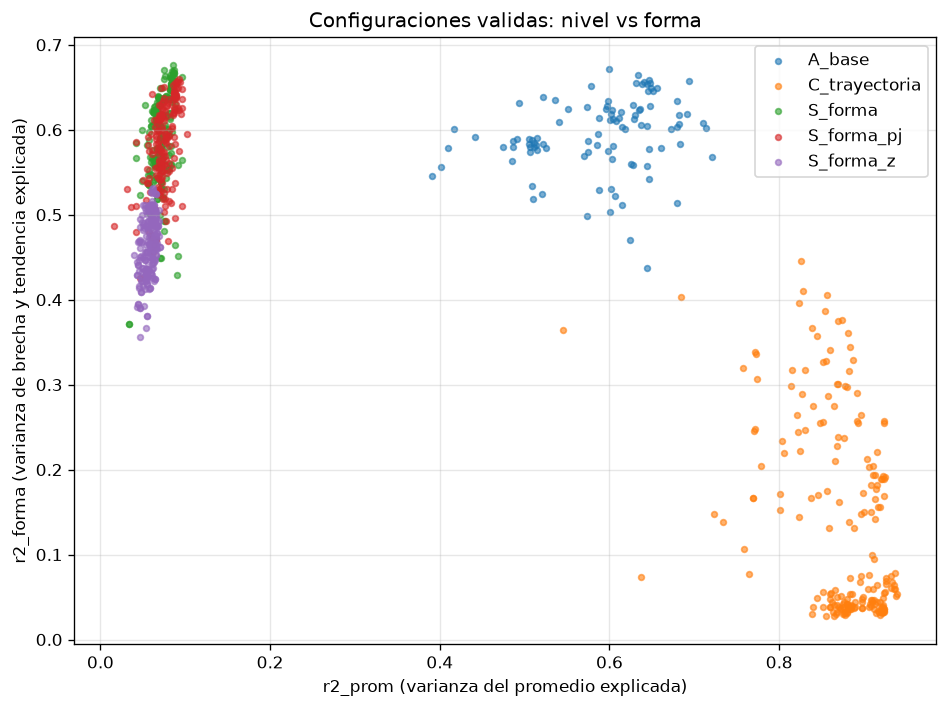

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
for conjunto, d in res[validas].groupby("conjunto"):
    ax.scatter(d["r2_prom"], d["r2_forma"], s=12, alpha=0.6, label=conjunto)
ax.set_xlabel("r2_prom (varianza del promedio explicada)")
ax.set_ylabel("r2_forma (varianza de brecha y tendencia explicada)")
ax.set_title("Configuraciones validas: nivel vs forma")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.4 Embeddings de la forma

UMAP (n_neighbors=15, min_dist=0.1, 2D) y t-SNE (perplejidad 30) de S_forma, coloreados por
brecha presidencial. Si hubiera grupos naturales se verian islas separadas.

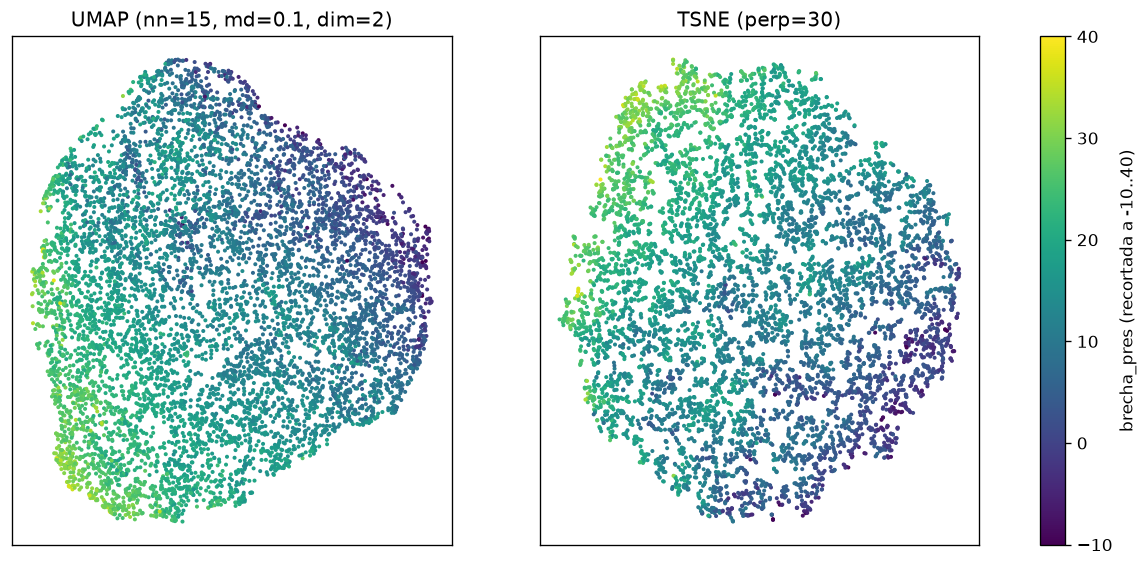

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
color = celdas.loc[idx_sub, "brecha_pres"].clip(-10, 40)
for ax, (emb, eprm) in zip(axes, [("umap", "nn=15, md=0.1, dim=2"), ("tsne", "perp=30")]):
    E = EMB_SUB[("S_forma", "estandar", emb, eprm)]
    sc = ax.scatter(E[:, 0], E[:, 1], c=color, s=2, cmap="viridis")
    ax.set_title(f"{emb.upper()} ({eprm})")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(sc, ax=axes, label="brecha_pres (recortada a -10..40)")
plt.show()

### 5.5 Top 15 por cada puntaje

In [16]:
COLS_TABLA = ["id", "conjunto", "prep", "embedding", "emb_params", "algoritmo", "params",
              "k_eff", "min_pct", "sil", "sil_nivel", "r2_prom", "sil_forma", "r2_forma",
              "v_edad", "v_sexo", "score_nivel", "score_forma"]
res[validas].nlargest(15, "score_forma")[COLS_TABLA].round(3)

,id,conjunto,prep,embedding,emb_params,algoritmo,params,k_eff,min_pct,sil,sil_nivel,r2_prom,sil_forma,r2_forma,v_edad,v_sexo,score_nivel,score_forma
1065,1065,S_forma,estandar_pca,ninguno,,kmeans,k=6,6,10.93,0.154,0.009,0.084,0.154,0.636,0.134,0.085,0.583,0.853
801,801,S_forma,estandar,ninguno,,kmeans,k=6,6,10.93,0.154,0.009,0.085,0.154,0.636,0.135,0.085,0.584,0.852
798,798,S_forma,estandar,ninguno,,kmeans,k=5,5,12.73,0.162,0.019,0.081,0.162,0.620,0.138,0.059,0.617,0.844
1062,1062,S_forma,estandar_pca,ninguno,,kmeans,k=5,5,12.74,0.162,0.019,0.081,0.162,0.619,0.138,0.059,0.618,0.841
795,795,S_forma,estandar,ninguno,,kmeans,k=4,4,18.03,0.172,0.026,0.068,0.172,0.606,0.135,0.051,0.583,0.834
1059,1059,S_forma,estandar_pca,ninguno,,kmeans,k=4,4,18.01,0.172,0.026,0.068,0.172,0.605,0.135,0.051,0.582,0.833
987,987,S_forma,estandar,umap,"nn=50, md=0.1, dim=5",kmeans,k=4,4,19.13,0.152,0.014,0.072,0.152,0.589,0.140,0.045,0.544,0.783
1251,1251,S_forma,estandar_pca,umap,"nn=50, md=0.1, dim=5",kmeans,k=4,4,19.49,0.151,0.012,0.071,0.151,0.588,0.141,0.044,0.528,0.779
963,963,S_forma,estandar,umap,"nn=50, md=0.1, dim=2",kmeans,k=4,4,19.54,0.154,0.019,0.069,0.154,0.574,0.135,0.038,0.551,0.768
891,891,S_forma,estandar,umap,"nn=15, md=0.1, dim=5",kmeans,k=4,4,19.79,0.150,0.013,0.071,0.150,0.581,0.142,0.041,0.530,0.767


In [17]:
res[validas].nlargest(15, "score_nivel")[COLS_TABLA].round(3)

,id,conjunto,prep,embedding,emb_params,algoritmo,params,k_eff,min_pct,sil,sil_nivel,r2_prom,sil_forma,r2_forma,v_edad,v_sexo,score_nivel,score_forma
531,531,C_trayectoria,estandar_pca,ninguno,,kmeans,k=4,4,17.55,0.299,0.199,0.897,-0.034,0.037,0.364,0.333,0.969,0.393
537,537,C_trayectoria,estandar_pca,ninguno,,kmeans,k=6,6,11.18,0.268,0.163,0.924,-0.045,0.255,0.286,0.333,0.965,0.419
534,534,C_trayectoria,estandar_pca,ninguno,,kmeans,k=5,5,15.68,0.285,0.183,0.893,-0.032,0.255,0.313,0.333,0.962,0.443
723,723,C_trayectoria,estandar_pca,umap,"nn=50, md=0.1, dim=5",kmeans,k=4,4,21.96,0.280,0.186,0.890,-0.030,0.038,0.367,0.329,0.961,0.401
699,699,C_trayectoria,estandar_pca,umap,"nn=50, md=0.1, dim=2",kmeans,k=4,4,21.05,0.275,0.184,0.884,-0.027,0.036,0.363,0.328,0.957,0.400
627,627,C_trayectoria,estandar_pca,umap,"nn=15, md=0.1, dim=5",kmeans,k=4,4,23.25,0.274,0.183,0.885,-0.028,0.040,0.364,0.327,0.955,0.407
629,629,C_trayectoria,estandar_pca,umap,"nn=15, md=0.1, dim=5",ward,k=4,4,13.83,0.283,0.189,0.881,-0.043,0.038,0.359,0.328,0.955,0.383
727,727,C_trayectoria,estandar_pca,umap,"nn=50, md=0.1, dim=5",gmm,k=5,5,10.12,0.252,0.159,0.916,-0.060,0.044,0.312,0.339,0.951,0.360
267,267,C_trayectoria,estandar,ninguno,,kmeans,k=4,4,17.48,0.236,0.199,0.897,-0.034,0.037,0.365,0.333,0.948,0.371
603,603,C_trayectoria,estandar_pca,umap,"nn=15, md=0.1, dim=2",kmeans,k=4,4,21.13,0.270,0.180,0.880,-0.025,0.048,0.362,0.327,0.947,0.420


## 6. Estabilidad

Candidatas: 8 mejores por score_forma, 4 mejores por score_nivel y la mejor por score_forma de
cada embedding. Se reajustan con 3 muestras nuevas (preprocesamiento, embedding y clustering)
y se compara con el ARI sobre la muestra eval.

In [18]:
v = res[validas]
mejores_emb = v.loc[v.groupby("embedding")["score_forma"].idxmax()]
candidatas = pd.concat([v.nlargest(8, "score_forma"), v.nlargest(4, "score_nivel"), mejores_emb])
candidatas = candidatas.drop_duplicates("id").reset_index(drop=True)


def reajustar(cid, seed):
    conjunto, prep, emb, eprm, algo, prm = CONFIGS[cid]
    idx_f, _ = muestra_ajuste(seed)
    X = celdas[CONJUNTOS[conjunto]].to_numpy(dtype=float)
    tr = (StandardScaler() if prep == "estandar"
          else make_pipeline(StandardScaler(), PCA(n_components=0.9, random_state=seed)))
    Z_f = tr.fit(X[idx_f]).transform(X[idx_f])
    E_s = None if emb == "ninguno" else embeber(emb, eprm, Z_f[:N_SUB], seed)
    modelo = ajustar(emb, algo, prm, Z_f, Z_f[:N_SUB], E_s, seed, {})
    return modelo.predict(tr.transform(X[idx_eval]))


aris = []
for cid in tqdm(candidatas["id"], desc="bootstrap"):
    a = [adjusted_rand_score(ETIQUETAS[cid], reajustar(cid, 1000 + b)) for b in range(N_BOOT)]
    aris.append({"id": cid, "ari_media": np.mean(a), "ari_min": np.min(a)})
candidatas = candidatas.merge(pd.DataFrame(aris), on="id")
candidatas[COLS_TABLA + ["ari_media", "ari_min"]].round(3)

bootstrap:   0%|          | 0/13 [00:00<?, ?it/s]

,id,conjunto,prep,embedding,emb_params,algoritmo,params,k_eff,min_pct,sil,sil_nivel,r2_prom,sil_forma,r2_forma,v_edad,v_sexo,score_nivel,score_forma,ari_media,ari_min
0,1065,S_forma,estandar_pca,ninguno,,kmeans,k=6,6,10.93,0.154,0.009,0.084,0.154,0.636,0.134,0.085,0.583,0.853,0.646,0.485
1,801,S_forma,estandar,ninguno,,kmeans,k=6,6,10.93,0.154,0.009,0.085,0.154,0.636,0.135,0.085,0.584,0.852,0.647,0.484
2,798,S_forma,estandar,ninguno,,kmeans,k=5,5,12.73,0.162,0.019,0.081,0.162,0.620,0.138,0.059,0.617,0.844,0.955,0.941
3,1062,S_forma,estandar_pca,ninguno,,kmeans,k=5,5,12.74,0.162,0.019,0.081,0.162,0.619,0.138,0.059,0.618,0.841,0.952,0.935
4,795,S_forma,estandar,ninguno,,kmeans,k=4,4,18.03,0.172,0.026,0.068,0.172,0.606,0.135,0.051,0.583,0.834,0.939,0.933
5,1059,S_forma,estandar_pca,ninguno,,kmeans,k=4,4,18.01,0.172,0.026,0.068,0.172,0.605,0.135,0.051,0.582,0.833,0.937,0.931
6,987,S_forma,estandar,umap,"nn=50, md=0.1, dim=5",kmeans,k=4,4,19.13,0.152,0.014,0.072,0.152,0.589,0.140,0.045,0.544,0.783,0.665,0.649
7,1251,S_forma,estandar_pca,umap,"nn=50, md=0.1, dim=5",kmeans,k=4,4,19.49,0.151,0.012,0.071,0.151,0.588,0.141,0.044,0.528,0.779,0.559,0.372
8,531,C_trayectoria,estandar_pca,ninguno,,kmeans,k=4,4,17.55,0.299,0.199,0.897,-0.034,0.037,0.364,0.333,0.969,0.393,0.976,0.959
9,537,C_trayectoria,estandar_pca,ninguno,,kmeans,k=6,6,11.18,0.268,0.163,0.924,-0.045,0.255,0.286,0.333,0.965,0.419,0.754,0.656


### 6.1 Finalistas

Entre las estables (ARI medio de al menos 0.8): las 2 mejores por score_forma y la mejor por
score_nivel.

In [19]:
estables = candidatas[candidatas["ari_media"] >= ARI_ESTABLE]
print(f"Estables: {len(estables)} de {len(candidatas)}")
fin_forma = estables.nlargest(2, "score_forma")
fin_nivel = estables[~estables["id"].isin(fin_forma["id"])].nlargest(1, "score_nivel")
finalistas = pd.concat([fin_forma.assign(lente="forma"), fin_nivel.assign(lente="nivel")])
finalistas[["lente"] + COLS_TABLA + ["ari_media"]].round(3)

Estables: 7 de 13


,lente,id,conjunto,prep,embedding,emb_params,algoritmo,params,k_eff,min_pct,sil,sil_nivel,r2_prom,sil_forma,r2_forma,v_edad,v_sexo,score_nivel,score_forma,ari_media
2,forma,798,S_forma,estandar,ninguno,,kmeans,k=5,5,12.73,0.162,0.019,0.081,0.162,0.620,0.138,0.059,0.617,0.844,0.955
3,forma,1062,S_forma,estandar_pca,ninguno,,kmeans,k=5,5,12.74,0.162,0.019,0.081,0.162,0.619,0.138,0.059,0.618,0.841,0.952
8,nivel,531,C_trayectoria,estandar_pca,ninguno,,kmeans,k=4,4,17.55,0.299,0.199,0.897,-0.034,0.037,0.364,0.333,0.969,0.393,0.976


## 7. Modelos finales

Las finalistas se reajustan para etiquetar todas las celdas. KMeans sin embedding usa todas
las celdas con `sample_weight` y `n_init=20`; GMM sin embedding, 200k filas ponderadas; las
demas, la muestra sub y KNN. Se agregan como referencia el modelo del notebook 04 y el
ganador del 05 (C_trayectoria, PCA, KMeans k=4).

In [20]:
def ajustar_final(conjunto, prep, emb, eprm, algo, prm):
    X = celdas[CONJUNTOS[conjunto]].to_numpy(dtype=float)
    tr = (StandardScaler() if prep == "estandar"
          else make_pipeline(StandardScaler(), PCA(n_components=0.9, random_state=RANDOM_STATE)))
    Z_all = tr.fit(X[idx_fit]).transform(X)
    if emb == "ninguno" and algo == "kmeans":
        modelo = ajustar(emb, algo, prm, Z_all, None, None, RANDOM_STATE, {},
                         w=celdas["peso"].to_numpy(), n_init=20)
    elif emb == "ninguno" and algo == "gmm":
        idx_big, _ = muestra_ajuste(RANDOM_STATE, n=N_FINAL)
        modelo = ajustar(emb, algo, prm, Z_all[idx_big], None, None, RANDOM_STATE, {}, n_init=5)
    else:
        Z_sub = Z_all[idx_sub]
        E_sub = None if emb == "ninguno" else embeber(emb, eprm, Z_sub, RANDOM_STATE)
        modelo = ajustar(emb, algo, prm, None, Z_sub, E_sub, RANDOM_STATE, {})
    return modelo.predict(Z_all), Z_all


modelos_finales = {
    "base_04": ("A_base", "estandar", "ninguno", {}, "kmeans", {"k": 4}),
    "ganador_05": ("C_trayectoria", "estandar_pca", "ninguno", {}, "kmeans", {"k": 4}),
}
for i, r in enumerate(finalistas.itertuples(), start=1):
    modelos_finales[f"{r.lente}_{i}"] = CONFIGS[r.id]

etiquetas_finales, metricas_finales = {}, []
for nombre, cfg in tqdm(modelos_finales.items(), desc="modelos finales"):
    labels, Z_all = ajustar_final(*cfg)
    etiquetas_finales[nombre] = labels
    conjunto, prep, emb, eprm, algo, prm = cfg
    metricas_finales.append({
        "modelo": nombre, "conjunto": conjunto, "prep": prep, "embedding": emb,
        "emb_params": texto(eprm), "algoritmo": algo, "params": texto(prm),
        **evaluar(labels[idx_eval], Z_all[idx_eval]),
    })
metricas_finales = pd.DataFrame(metricas_finales)
metricas_finales.round(3)

modelos finales:   0%|          | 0/5 [00:00<?, ?it/s]

,modelo,conjunto,prep,embedding,emb_params,algoritmo,params,k_eff,pct_ruido,min_pct,sil,db,sil_nivel,r2_prom,sil_forma,r2_forma,v_edad,v_sexo
0,base_04,A_base,estandar,ninguno,,kmeans,k=4,4,0.0,18.21,0.261,1.144,0.128,0.574,0.063,0.575,0.284,0.257
1,ganador_05,C_trayectoria,estandar_pca,ninguno,,kmeans,k=4,4,0.0,17.74,0.299,1.055,0.198,0.897,-0.034,0.037,0.364,0.331
2,forma_1,S_forma,estandar,ninguno,,kmeans,k=5,5,0.0,12.50,0.162,1.631,0.019,0.081,0.162,0.620,0.139,0.055
3,forma_2,S_forma,estandar_pca,ninguno,,kmeans,k=5,5,0.0,12.50,0.162,1.631,0.019,0.081,0.162,0.620,0.139,0.055
4,nivel_3,C_trayectoria,estandar_pca,ninguno,,kmeans,k=4,4,0.0,17.74,0.299,1.055,0.198,0.897,-0.034,0.037,0.364,0.331


### 7.1 Coincidencia entre modelos (ARI)

In [21]:
nombres = list(etiquetas_finales)
pd.DataFrame(
    [[adjusted_rand_score(etiquetas_finales[a][idx_eval], etiquetas_finales[b][idx_eval])
      for b in nombres] for a in nombres],
    index=nombres, columns=nombres,
).round(3)

,base_04,ganador_05,forma_1,forma_2,nivel_3
base_04,1.000,0.216,0.211,0.211,0.216
ganador_05,0.216,1.000,0.027,0.027,1.000
forma_1,0.211,0.027,1.000,1.000,0.027
forma_2,0.211,0.027,1.000,1.000,0.027
nivel_3,0.216,1.000,0.027,0.027,1.000


### 7.2 Perfiles de cada modelo

Resumen ponderado, ordenado por promedio de participacion.

In [22]:
def resumen_perfiles(labels):
    df = celdas.assign(perfil=labels)
    df = df[df["perfil"] >= 0]
    filas = []
    for p, dp in df.groupby("perfil"):
        w = dp["peso"]
        filas.append({
            "pct_pob": w.sum() / df["peso"].sum() * 100,
            "promedio": np.average(dp["promedio"], weights=w),
            "brecha_pres": np.average(dp["brecha_pres"], weights=w),
            "tendencia": np.average(dp["tendencia"], weights=w),
            "desviacion": np.average(dp["desviacion"], weights=w),
            "P_PJ2025": np.average(dp["P_PJ2025"], weights=w),
            "pct_mujer": np.average(dp["MUJER"], weights=w) * 100,
            "pct_rural_mixta": np.average(dp["TIPOSEC"].astype(str) != "U", weights=w) * 100,
            "edad_dominante": dp.groupby("GRUPO_EDAD")["peso"].sum().idxmax(),
        })
    return pd.DataFrame(filas).sort_values("promedio").reset_index(drop=True).round(1)


for nombre, labels in etiquetas_finales.items():
    conjunto, prep, emb, eprm, algo, prm = modelos_finales[nombre]
    print(f"\n{nombre}: {conjunto} | {prep} | {emb} {texto(eprm)} | {algo} {texto(prm)}")
    print(resumen_perfiles(labels).to_string())


base_04: A_base | estandar | ninguno  | kmeans k=4
   pct_pob  promedio  brecha_pres  tendencia  desviacion  P_PJ2025  pct_mujer  pct_rural_mixta edad_dominante
0     27.4      42.0         15.3        1.2        10.7      11.7       34.8             23.4          30-39
1     19.3      54.4          4.8       -1.7         8.2      10.6       46.1             44.7          30-39
2     25.4      56.9         22.0        4.4        15.3      14.9       62.0             20.4          30-39
3     27.9      69.4         10.0        1.9         9.0      14.6       65.1             35.8          50-59

ganador_05: C_trayectoria | estandar_pca | ninguno  | kmeans k=4
   pct_pob  promedio  brecha_pres  tendencia  desviacion  P_PJ2025  pct_mujer  pct_rural_mixta edad_dominante
0     17.8      35.7         13.4        0.9        10.5      10.8       22.2             29.1          30-39
1     30.4      49.3         15.5        1.6        11.8      12.7       47.9             25.0          30-39
2 

   pct_pob  promedio  brecha_pres  tendencia  desviacion  P_PJ2025  pct_mujer  pct_rural_mixta edad_dominante
0     28.8      51.2         20.9        1.8        12.7      13.2       52.7             13.6          30-39
1     21.2      53.8          7.5       -1.8         8.8      10.3       47.4             41.3          30-39
2     16.1      57.7         18.6        5.1        14.8      15.8       56.2             29.7          30-39
3     12.3      59.5         10.0        3.2        11.9      14.7       54.9             48.7          30-39
4     21.6      60.5          7.7        1.3         7.0      12.8       52.6             31.3          60-69

forma_2: S_forma | estandar_pca | ninguno  | kmeans k=5
   pct_pob  promedio  brecha_pres  tendencia  desviacion  P_PJ2025  pct_mujer  pct_rural_mixta edad_dominante
0     28.8      51.2         20.9        1.8        12.7      13.2       52.7             13.6          30-39
1     21.2      53.8          7.5       -1.8         8.8      1

### 7.3 Trayectorias de los perfiles de forma

Trayectoria ponderada de cada perfil de los finalistas de forma, junto al modelo del notebook 04.

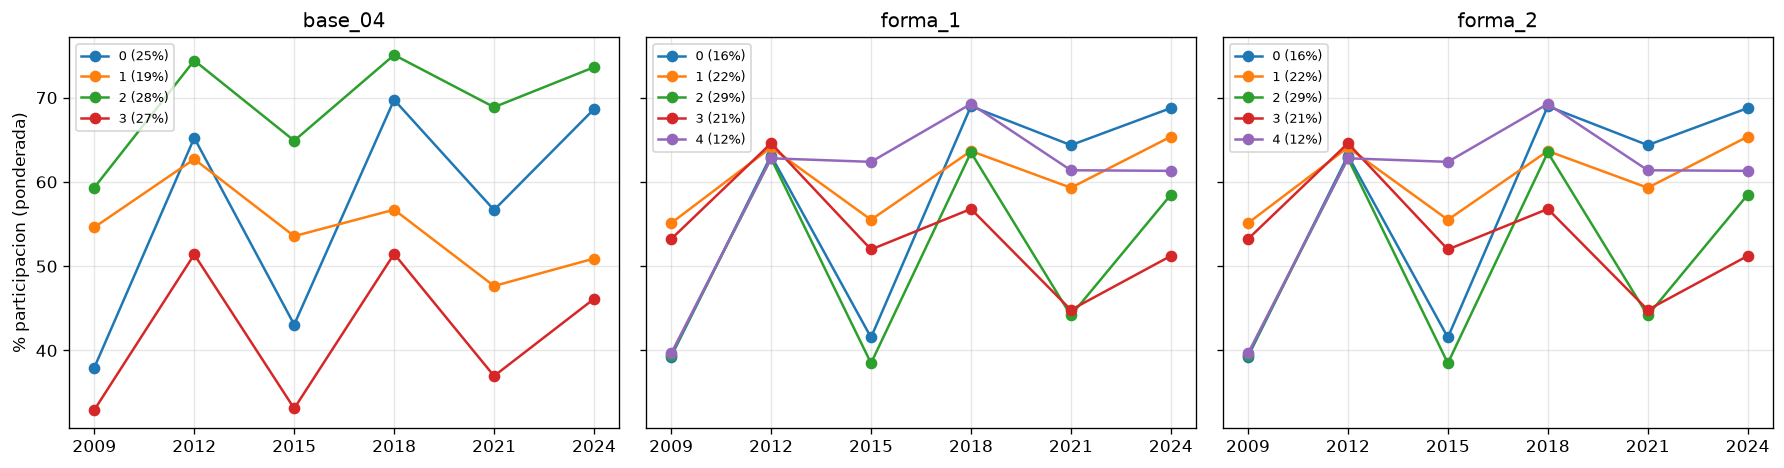

In [23]:
anos = [2009, 2012, 2015, 2018, 2021, 2024]
graficar = ["base_04"] + [n for n in etiquetas_finales if n.startswith("forma")]
fig, axes = plt.subplots(1, len(graficar), figsize=(5 * len(graficar), 4), sharey=True)
for ax, nombre in zip(np.atleast_1d(axes), graficar):
    df = celdas.assign(perfil=etiquetas_finales[nombre])
    for p, dp in df[df["perfil"] >= 0].groupby("perfil"):
        tray = [np.average(dp[e], weights=dp["peso"]) for e in ELECCIONES]
        share = dp["peso"].sum() / df["peso"].sum() * 100
        ax.plot(anos, tray, "o-", label=f"{p} ({share:.0f}%)")
    ax.set_title(nombre)
    ax.set_xticks(anos)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel("% participacion (ponderada)")
plt.tight_layout()
plt.show()

## 8. Exportacion

In [24]:
res.to_csv(DIR_PREPROCESSED / "experimentos_forma_embeddings.csv", index=False)
candidatas.to_csv(DIR_PREPROCESSED / "experimentos_forma_estabilidad.csv", index=False)
metricas_finales.to_csv(DIR_PREPROCESSED / "experimentos_forma_finalistas.csv", index=False)

salida = celdas[["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD", "peso"]].copy()
for nombre, labels in etiquetas_finales.items():
    salida[nombre] = labels.astype("int8")
salida.to_parquet(DIR_PREPROCESSED / "celdas_perfiles_candidatos_forma.parquet", index=False)

for f in ["experimentos_forma_embeddings.csv", "experimentos_forma_estabilidad.csv",
          "experimentos_forma_finalistas.csv", "celdas_perfiles_candidatos_forma.parquet"]:
    print(f"{f}: {(DIR_PREPROCESSED / f).stat().st_size / 1024:.0f} KB")

experimentos_forma_embeddings.csv: 651 KB
experimentos_forma_estabilidad.csv: 4 KB
experimentos_forma_finalistas.csv: 1 KB
celdas_perfiles_candidatos_forma.parquet: 2185 KB
